In [2]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2
from src.spectral import mean_cross_spectral
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, csd

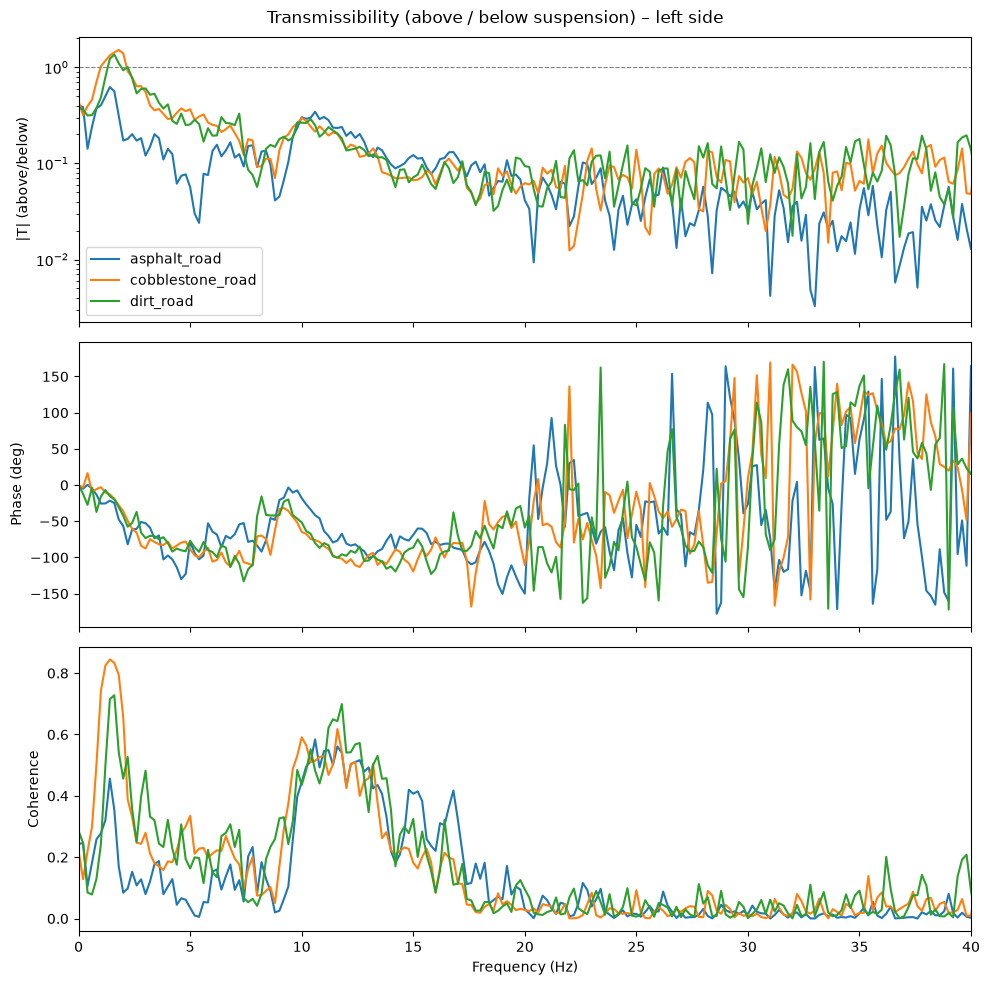

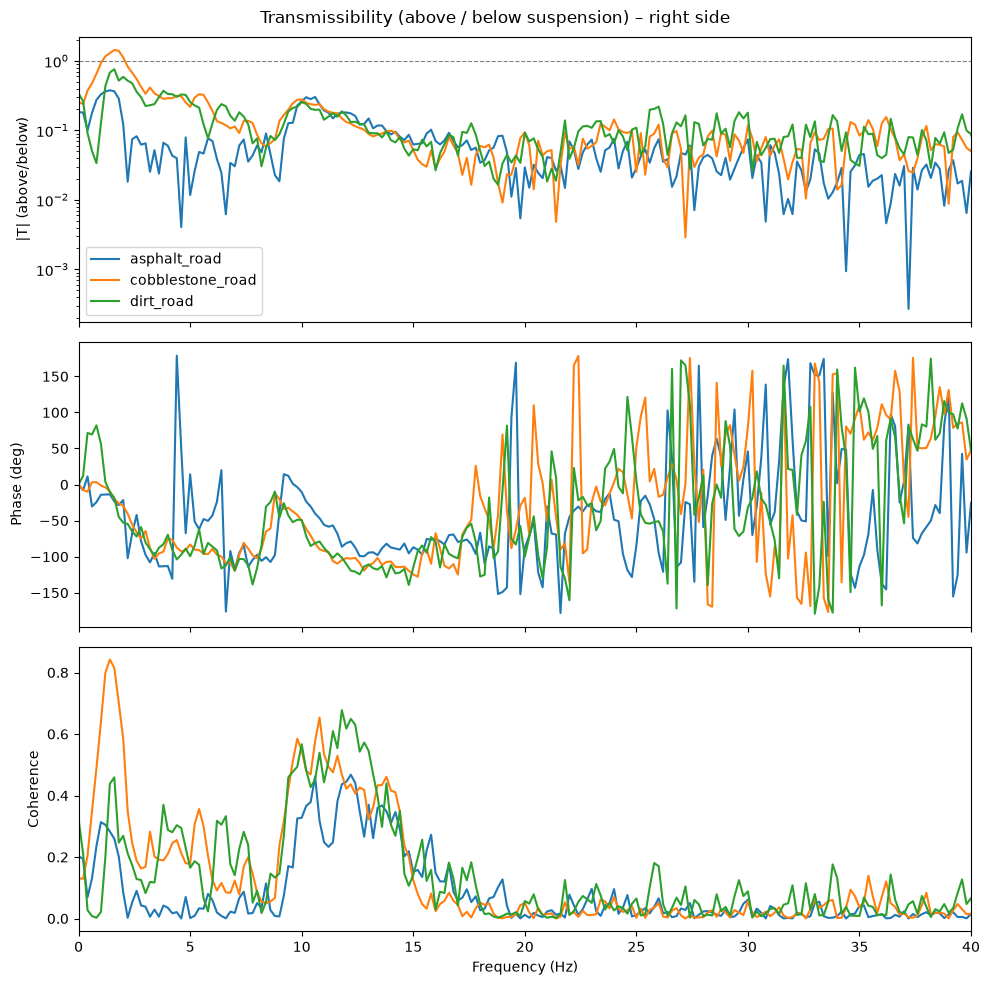

In [3]:
data={}
for side in ['left', 'right']:
    signals = pd.read_parquet(f'../data/processed/signals_PVS1_{side}.parquet')
    windows = pd.read_csv(f'../data/processed/windows_PVS1_{side}.csv', index_col='window')
    data[side] = (signals, windows)

    col_in, col_out = 'acc_z_below_suspension_filt', 'acc_z_above_suspension_filt'
    surfaces = ['asphalt_road', 'cobblestone_road', 'dirt_road']

    fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex = True)
    for surf in surfaces:
        ids = windows[windows['valid'] & (windows['surface'] == surf)].index
        f, Pxx, Pyy, Pxy = mean_cross_spectral(signals, ids, col_in=col_in, col_out=col_out)
        H1 = Pxy/Pxx
        coh = np.abs(Pxy)**2/(Pxx * Pyy)

        axes[0].semilogy(f, np.abs(H1), label = surf)
        axes[1].plot(f, np.degrees(np.angle(H1)))
        axes[2].plot(f, coh)

    axes[0].axhline(1, c='grey', ls ='--', lw=0.8)
    axes[0].set_ylabel('|T| (above/below)')
    axes[1].set_ylabel('Phase (deg)')
    axes[2].set_ylabel('Coherence')
    axes[2].set_xlabel('Frequency (Hz)')
    axes[2].set_xlim(0, 40)
    axes[0].legend()
    fig.suptitle(f'Transmissibility (above / below suspension) – {side} side')
    plt.tight_layout()
    plt.show


In [5]:
from src.spectral import half_power_damping

rows = []
for side, (signals, windows) in data.items():
    for surf in surfaces:
        ids = windows[windows['valid'] & (windows['surface'] == surf)].index
        f, Pxx, Pyy, Pxy = mean_cross_spectral(signals, ids, col_in, col_out)
        mag = np.abs(Pxy / Pxx)
        coh = np.abs(Pxy)**2 / (Pxx * Pyy)

        fn, peak, zeta, f1, f2 = half_power_damping(f, mag, 0.5, 3)
        coh_at_peak = coh[np.argmin(np.abs(f - fn))]

        rows.append({'side': side, 'surface': surf, 'fn_hz': fn, 'T_peak': peak,
                     'f1_hz': f1, 'f2_hz': f2, 'zeta': zeta, 'coherence_at_peak': coh_at_peak})

body_mode = pd.DataFrame(rows)
display(body_mode.round(3))

,side,surface,fn_hz,T_peak,f1_hz,f2_hz,zeta,coherence_at_peak
0,left,asphalt_road,1.4,0.622,1.076,1.698,0.222,0.456
1,left,cobblestone_road,1.8,1.514,1.063,2.133,0.297,0.794
2,left,dirt_road,1.6,1.357,1.278,1.965,0.215,0.728
3,right,asphalt_road,1.4,0.378,0.785,1.824,0.371,0.283
4,right,cobblestone_road,1.6,1.438,1.076,2.072,0.311,0.815
5,right,dirt_road,1.6,0.758,1.282,1.787,0.158,0.459


In [6]:
rows = []
for side, (signals, windows) in data.items():
    for surf in surfaces:
        ids = windows[windows['valid'] & (windows['surface'] == surf)].index
        f, Pxx, Pyy, Pxy = mean_cross_spectral(signals, ids, col_in, col_out)
        mag = np.abs(Pxy / Pxx)
        coh = np.abs(Pxy)**2 / (Pxx * Pyy)

        fn, peak, zeta, f1, f2 = half_power_damping(f, mag, 7, 15)
        coh_at_peak = coh[np.argmin(np.abs(f - fn))]

        rows.append({'side': side, 'surface': surf, 'fn_hz': fn, 'T_peak': peak,
                     'f1_hz': f1, 'f2_hz': f2, 'zeta': zeta, 'coherence_at_peak': coh_at_peak})

body_mode = pd.DataFrame(rows)
display(body_mode.round(3))

,side,surface,fn_hz,T_peak,f1_hz,f2_hz,zeta,coherence_at_peak
0,left,asphalt_road,10.6,0.344,9.828,11.366,0.073,0.584
1,left,cobblestone_road,10.0,0.297,9.452,11.076,0.081,0.591
2,left,dirt_road,7.2,0.330,6.270,7.297,0.071,0.290
3,right,asphalt_road,10.6,0.303,9.773,10.905,0.053,0.462
4,right,cobblestone_road,10.0,0.280,9.391,11.049,0.083,0.547
5,right,dirt_road,10.0,0.256,9.378,10.864,0.074,0.567


## Part 4 – Conclusions (PVS 1)

1. **Body mode:** on cobblestone the body (sprung-mass) mode is at 1.6–1.8 Hz on both sides, with a transmissibility peak of 1.44–1.51 (≈ 45–50 % amplification) and high coherence (0.79–0.82). On dirt, only the left side gives a reliable estimate (1.6 Hz, |T| = 1.36, coherence 0.73).
2. **Isolation:** above ~3 Hz the transmissibility drops below 1, staying at ~0.1–0.3 between 5 and 15 Hz: the suspension transmits only 10–30 % of the wheel vibration in this range.
3. **Origin of the ~10 Hz body peak (Part 3):** the transmissibility shows a local maximum at ~10–12 Hz (|T| ≈ 0.3) with coherence of 0.5–0.7. The ~10 Hz peak measured above the suspension is therefore wheel-hop vibration (13–16 Hz below the suspension) transmitted to the body, not an independent source.
4. **Damping (single-degree-of-freedom estimates):** the half-power bandwidth method gives ζ ≈ 0.22–0.31, while the peak height gives ζ ≈ 0.44–0.54. The disagreement shows the limits of the single-degree-of-freedom assumption (coupling with the wheel, input from the other wheels, possible underestimation of |T| by the H1 estimator). A quarter-car model fit is used in Part 7.
5. **Reliability:** results are only interpreted where coherence exceeds ~0.5. On asphalt, coherence at the body mode is low (0.28–0.46): low-frequency excitation is weak and not dominated by this wheel, so the estimates are unreliable. Above ~20 Hz coherence is close to zero on all surfaces, so transmissibility and phase are not meaningful; vibration there likely comes from other sources (other wheels, engine and driveline, structural modes, sensor noise).